In [1]:
import seaborn as sb
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
titanic = sb.load_dataset("titanic")
X = titanic.drop(["survived", "alive"], axis=1)
y = titanic["survived"]
numerical_columns = X.select_dtypes(include=["int64", "float64"]).columns
categorical_columns = X.select_dtypes(include=["object", "string", "category"]).columns
numerical_pipeline = Pipeline([("imputer", SimpleImputer(strategy="median")),("scaler", StandardScaler())])
categorical_pipeline = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),("encoder", OneHotEncoder(handle_unknown="ignore"))])
preprocessor = ColumnTransformer([("num", numerical_pipeline, numerical_columns),("cat", categorical_pipeline, categorical_columns)])
X_train, X_test, y_train, y_test = train_test_split( X, y,test_size=0.2,random_state=42,stratify=y)
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)
if hasattr(X_train_processed, "toarray"):
    X_train_processed = X_train_processed.toarray()
if hasattr(X_test_processed, "toarray"):
    X_test_processed = X_test_processed.toarray()
X_train_tensor = torch.tensor(np.asarray(X_train_processed, dtype=np.float32),dtype=torch.float32)
X_test_tensor = torch.tensor(np.asarray(X_test_processed, dtype=np.float32),dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.to_numpy(),dtype=torch.long)
y_test_tensor = torch.tensor(y_test.to_numpy(),dtype=torch.long)
print("Training features:", X_train_tensor.shape)
print("Testing features:", X_test_tensor.shape)
print("Training labels:", y_train_tensor.shape)
print("Testing labels:", y_test_tensor.shape)


Training features: torch.Size([712, 26])
Testing features: torch.Size([179, 26])
Training labels: torch.Size([712])
Testing labels: torch.Size([179])


In [7]:
#9.	Define a class inheriting from nn.Module with two or three linear layers and ReLU between them, 
#ending in an output layer sized to your number of classes.
import torch.nn as nn
class TitanicNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.network=nn.Sequential(nn.Linear(26,16),nn.ReLU(),nn.Linear(16,8),nn.ReLU(),nn.Linear(8,2))
    def forward(self,x):
        return self.network(x)
model=TitanicNN()
print(model)
              
        

TitanicNN(
  (network): Sequential(
    (0): Linear(in_features=26, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=8, bias=True)
    (3): ReLU()
    (4): Linear(in_features=8, out_features=2, bias=True)
  )
)


In [8]:
#10.Choose cross entropy as your loss and Adam as your optimizer, with a learning rate of around one thousandth.
import torch
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(),lr=0.001)
print("Loss function:", loss_fn)
print("Optimizer:", optimizer)

Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


Epoch: 50, Loss: 0.5595
Epoch: 100, Loss: 0.4165
Epoch: 150, Loss: 0.3889
Epoch: 200, Loss: 0.3798
Epoch: 250, Loss: 0.3719
Epoch: 300, Loss: 0.3643


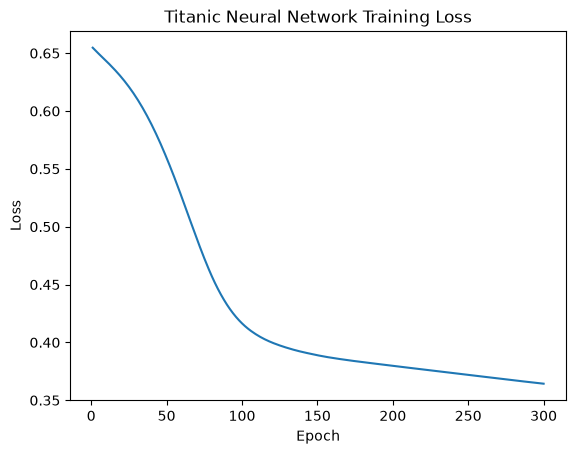

In [10]:
#11.Write the training loop over a few hundred passes, recording the loss each time, then plot the loss curve.

import matplotlib.pyplot as plt

losses = []

for epoch in range(300):
    model.train()

    optimizer.zero_grad()

    predictions = model(X_train_tensor)

    loss = loss_fn(predictions, y_train_tensor)

    loss.backward()

    optimizer.step()

    losses.append(loss.item())

    if (epoch + 1) % 50 == 0:
        print(f"Epoch: {epoch + 1}, Loss: {loss.item():.4f}")

plt.plot(range(1, 301), losses)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Titanic Neural Network Training Loss")
plt.show()



In [12]:
#12.Evaluate accuracy on the test set, remembering to switch the model into evaluation mode and to turn gradient tracking off while you do it.
from sklearn.metrics import accuracy_score, classification_report
model.eval()
with torch.no_grad():
    predictions=model(X_test_tensor)
    y_pred=torch.argmax(predictions,dim=1)
accuracy=accuracy_score(y_test_tensor.numpy(),y_pred.numpy())
print(f"Test Accuracy: {accuracy:.4f}")
print(f"Test Accuracy: {accuracy * 100:.2f}%")

Test Accuracy: 0.8268
Test Accuracy: 82.68%


In [16]:
#14.	Change the width of the hidden layer, then change the number of layers, and note which of the two mattered more.
# 1. Wider hidden layers: 26 -> 32 -> 16 -> 2
wide_model = nn.Sequential(
    nn.Linear(26, 32),
    nn.ReLU(),
    nn.Linear(32, 16),
    nn.ReLU(),
    nn.Linear(16, 2))

shallow_model = nn.Sequential(
    nn.Linear(26, 16),
    nn.ReLU(),
    nn.Linear(16, 2))
loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(wide_model.parameters(), lr=0.001)
for epoch in range(50):
    predictions = wide_model(X_train_tensor)
    loss = loss_fn(predictions, y_train_tensor)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
wide_model.eval()
with torch.no_grad():
    predictions = wide_model(X_test_tensor)
    wide_accuracy = (predictions.argmax(1) == y_test_tensor).float().mean().item()
print(f"Wider Model Accuracy: {wide_accuracy * 100:.2f}%")
# Train Shallow Model
optimizer = torch.optim.Adam(shallow_model.parameters(), lr=0.001)
for epoch in range(50):
    predictions = shallow_model(X_train_tensor)
    loss = loss_fn(predictions, y_train_tensor)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
shallow_model.eval()
with torch.no_grad():
    predictions = shallow_model(X_test_tensor)
    shallow_accuracy = (predictions.argmax(1) == y_test_tensor).float().mean().item()
print(f"Shallow Model Accuracy: {shallow_accuracy * 100:.2f}%")

Wider Model Accuracy: 78.21%
Shallow Model Accuracy: 73.74%
